# CPTAC 固定候选池归一化复评

## tl;dr

完整 portrait 的 pooled nDCG@10 从 0.169 升至 0.218，但低于 CellWhisperer 0.307、传统组合 0.631 和 marker-rank 0.655。输入修复没有证明原计划要求的实用增益；不据此启动扩大投入或把稿件标为 Cell-ready。

## Context & Methods

### Key Assumptions

同一组 942 个候选、30 个问题和每题 3 个改写，18 个旧条件加 14 个新条件。归一化在全候选池拟合，属于传导式方案。本轮已见过旧结果，不是确认性研究。每题各方法共用可测蛋白证据池；缺失不补成阴性。

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import Image, display
root = Path.cwd()
report = json.loads((root/'analysis_summary.json').read_text())
assert report['complete_portrait_inferences']==3768 and report['failed_inferences']==0
assert report['independently_verified_metric_groups']==37440
assert report['max_independent_metric_abs_error']<1e-12
assert report['old_metric_groups_reproduced']==21060
assert not report['Cell_utility_gate_passed']
print('推断、独立指标重建及旧结果回归检查通过；实用价值门槛未通过。')

推断、独立指标重建及旧结果回归检查通过；实用价值门槛未通过。


## Data

可判断病例数随问题为 146–942。30 个问题也共享生物学面板，90 种文字改写不是 90 个独立实验。

In [2]:
all_conditions = pd.read_csv(root/'primary_all_conditions.csv').set_index('method')
assert len(all_conditions)==32
print('候选数:', report['candidate_cases'], '; 每题可判断范围:', report['judged_cases_per_pooled_query_range'])
all_conditions[['conditional_ndcg_at_10','conditional_precision_at_10','full_pool_top10_judged_fraction','conditional_top10_jaccard']].round(4)

候选数: 942 ; 每题可判断范围: [146, 942]


,conditional_ndcg_at_10,conditional_precision_at_10,full_pool_top10_judged_fraction,conditional_top10_jaccard
method,,,,
cellwhisperer_v1,0.3070,0.4067,0.7589,0.2394
combined_conventional,0.6310,0.7667,0.8067,1.0000
compact_marker_rank,0.6546,0.8000,0.7933,1.0000
compact_marker_zscore,0.5997,0.7200,0.7767,1.0000
fixed_conventional_text_minilm,0.2408,0.4000,0.7233,0.2261
full_portrait_no_calibration_sf_full_measured,0.2116,0.3422,0.7689,0.3834
full_portrait_no_calibration_sf_reference,0.2175,0.3500,0.7678,0.3776
full_portrait_released_calibration_sf_full_measured,0.2116,0.3422,0.7689,0.3834
full_portrait_released_calibration_sf_reference,0.2175,0.3500,0.7678,0.3776


## Results

### 归一化与同任务比较

图仅用于本轮探索性复评，不替换原计划中的六个投稿主图。完整条件表保留打乱、错配、屏蔽和两种校准设置。

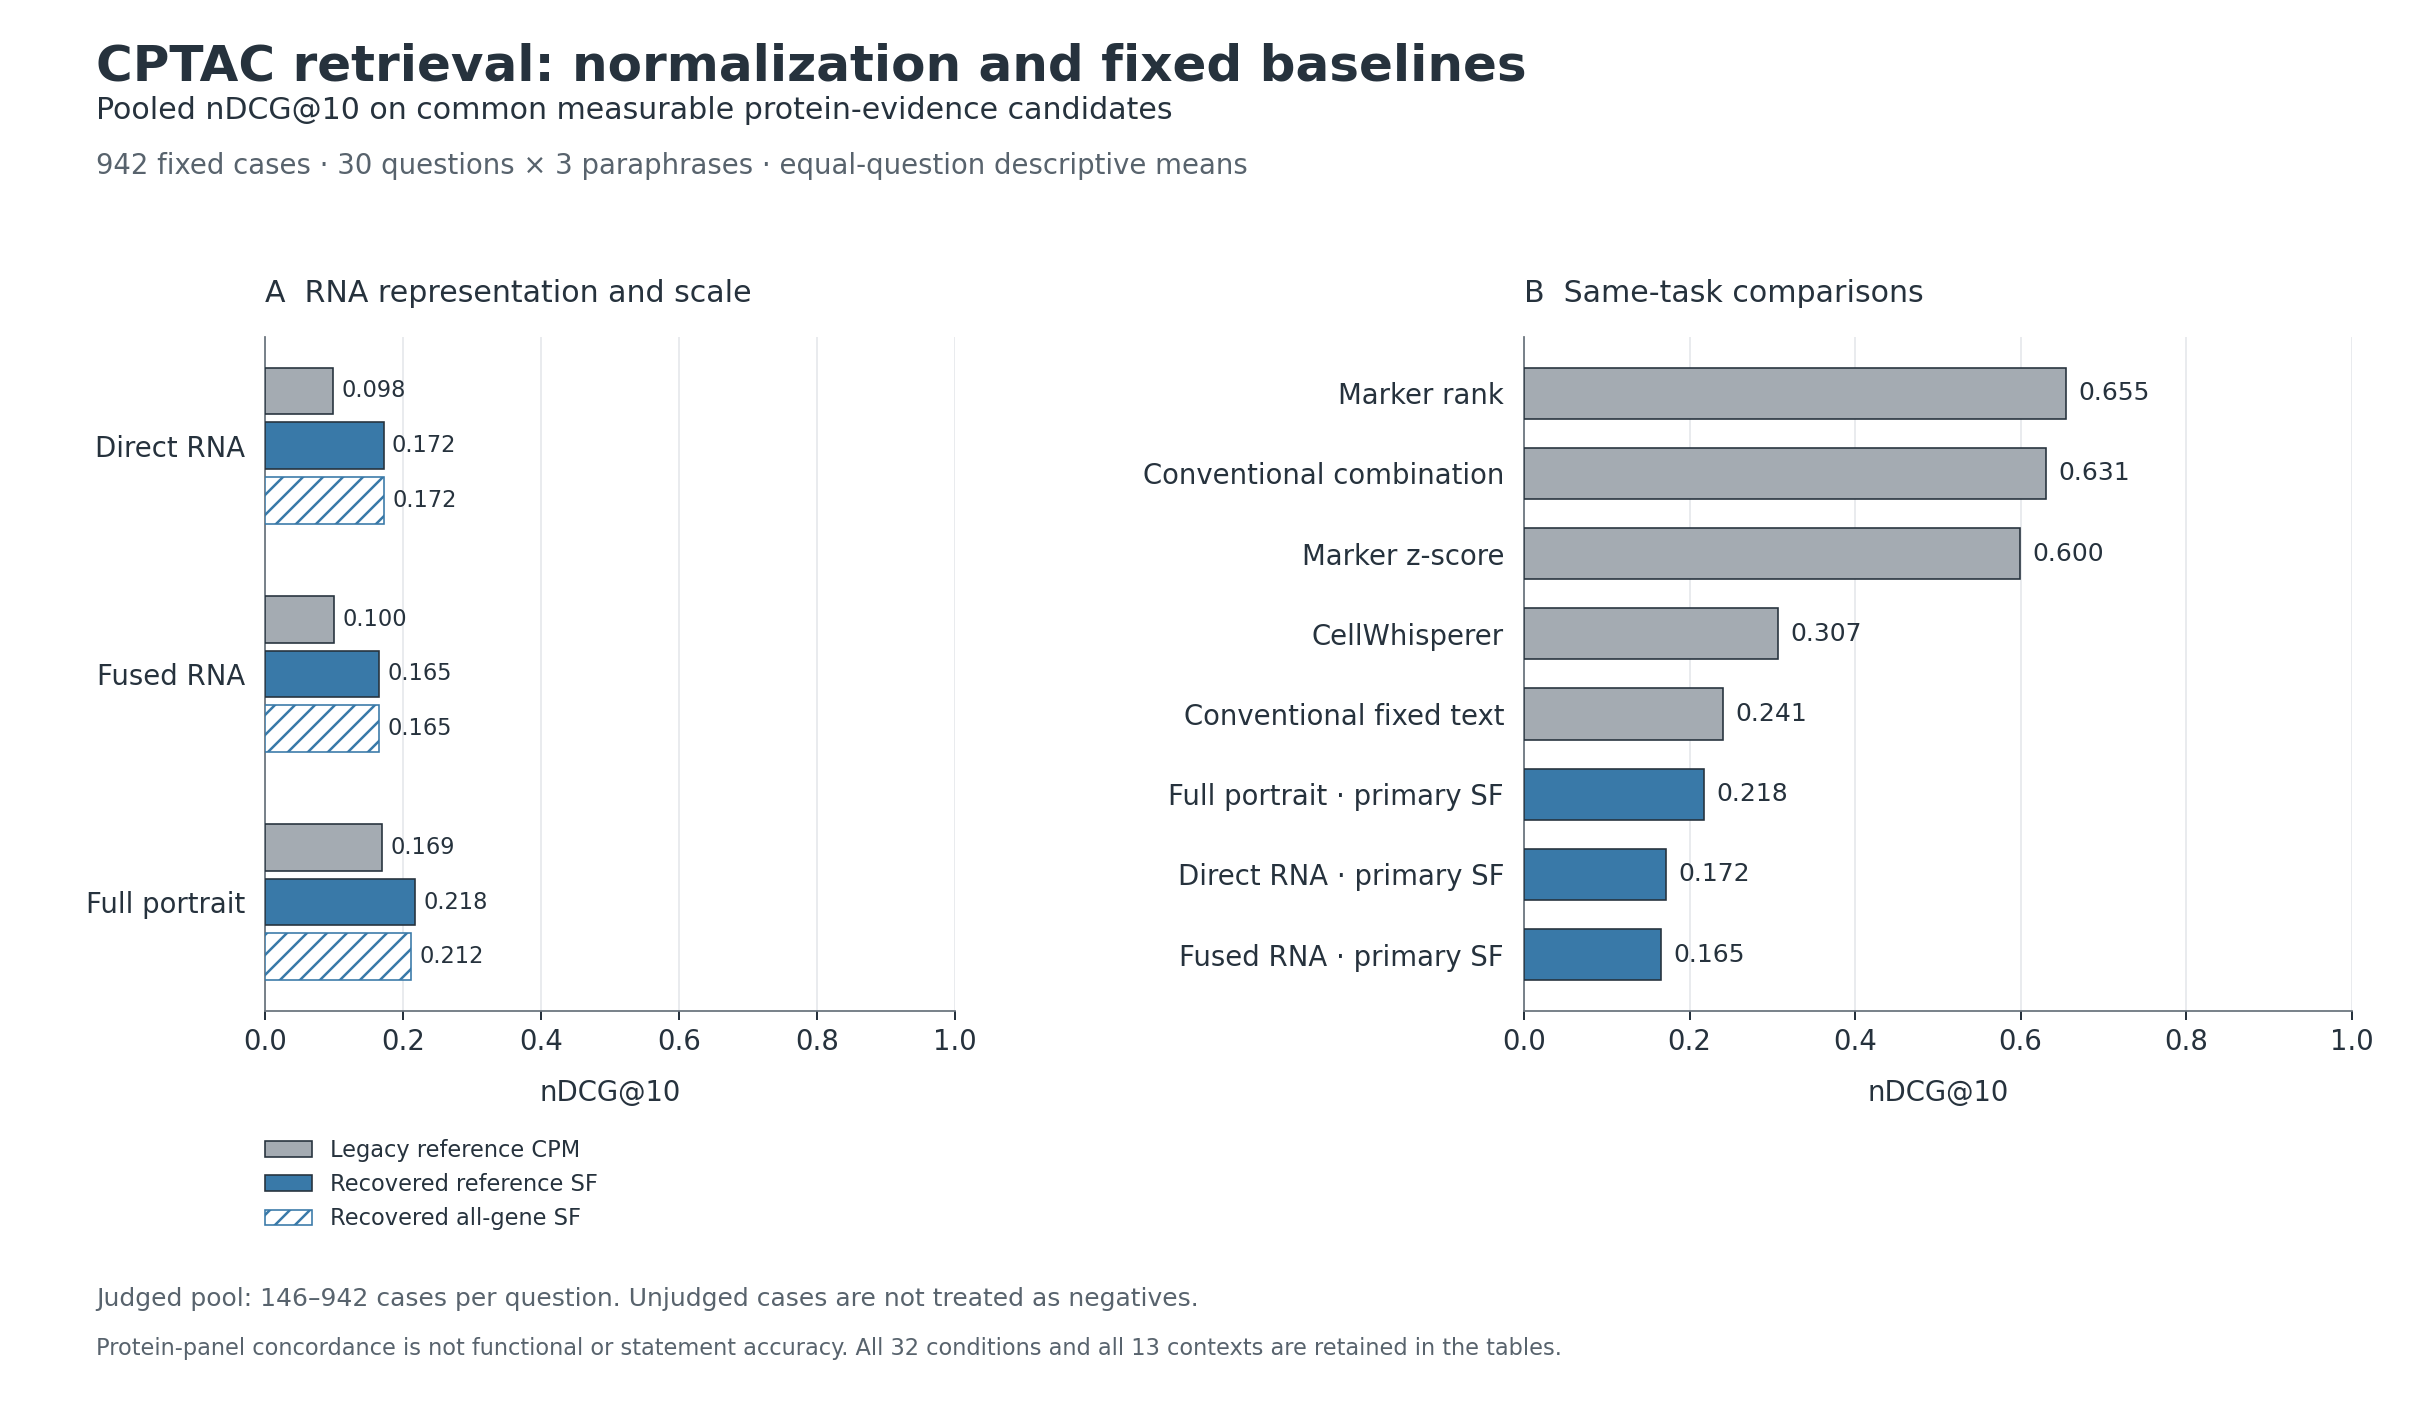

In [3]:
display(Image(filename=str(root/'cptac_reassessment_overview.png')))

### 分层结果

未关联病例不等于已证明未暴露。within-cohort 使用原有队列内蛋白参照，不能择优替换 pooled 主分析。

In [4]:
strata = pd.read_csv(root/'prespecified_comparators_by_context.csv')
strata.pivot(index='method',columns=['scope','stratum'],values='conditional_ndcg_at_10').round(4)

scope                                            pooled  \
stratum                                             all   
method                                                    
cellwhisperer_v1                                 0.3070   
combined_conventional                            0.6310   
compact_marker_rank                              0.6546   
compact_marker_zscore                            0.5997   
fixed_conventional_text_minilm                   0.2408   
full_portrait_released_calibration_sf_reference  0.2175   
rna_direct_sf_reference                          0.1716   
rna_fused_sf_reference                           0.1655   

scope                                                                   \
stratum                                         no_recorded_case_match   
method                                                                   
cellwhisperer_v1                                                0.3025   
combined_conventional                                           0.6035   
compact_marker_rank                                             0.5980   
compact_marker_zscore                                           0.5801   
fixed_conventional_text_minilm                                  0.1928   
full_portrait_released_calibration_sf_reference                 0.2440   
rna_direct_sf_reference                                         0.1614   
rna_fused_sf_reference                                          0.1606   

scope                                                                 \
stratum                                         prior_alignment_test   
method                                                                 
cellwhisperer_v1                                              0.3441   
combined_conventional                                         0.7293   
compact_marker_rank                                           0.7110   
compact_marker_zscore                                         0.7322   
fixed_conventional_text_minilm                                0.2975   
full_portrait_released_calibration_sf_reference               0.1943   
rna_direct_sf_reference                                       0.1804   
rna_fused_sf_reference                                        0.1727   

scope                                           within_cohort  
stratum                                                   all  
method                                                         
cellwhisperer_v1                                       0.3630  
combined_conventional                                  0.7172  
compact_marker_rank                                    0.7214  
compact_marker_zscore                                  0.7279  
fixed_conventional_text_minilm                         0.3245  
full_portrait_released_calibration_sf_reference        0.2784  
rna_direct_sf_reference                                0.2423  
rna_fused_sf_reference                                 0.2481

### 逐问题差异

先在问题内平均改写，再比较问题。下表是描述性计数，不是独立问题的显著性检验。

In [5]:
pd.read_csv(root/'paired_question_comparisons.csv')[['comparator','queries','wins','ties','losses','mean_ndcg_difference']].round(4)

,comparator,queries,wins,ties,losses,mean_ndcg_difference
0,full_portrait_text_released_calibration,30,18,0,12,0.0481
1,compact_marker_rank,30,3,0,27,-0.4370
2,combined_conventional,30,3,0,27,-0.4135
3,cellwhisperer_v1,30,13,0,17,-0.0895


### 校准与描述

这里比较完整的六字段检索文本，不声称所有内部校准数值都相同。

In [6]:
assert report['identical_six_field_texts_with_calibration_on_off']=={'sf_reference':942,'sf_full_measured':942}
pd.DataFrame.from_dict(report['unique_portrait_texts'],orient='index',columns=['unique_six_field_texts'])

,unique_six_field_texts
full_portrait_no_calibration_sf_full_measured,818
full_portrait_no_calibration_sf_reference,821
full_portrait_released_calibration_sf_full_measured,818
full_portrait_released_calibration_sf_reference,821


## Takeaways

本轮数字经独立实现核对，但生物学实用性没有通过推进标准。保留全部弱结果、旧 CPM 结果和失败条件，不通过删选查询、换主分析或追加拒答来制造增益。后续研究路线和 Cell 定位需要作者决定。原稿未改写，未启动重训；人工语句盲评、独立确认性收益和投稿材料尚未完成。